## IMD Best track of Cylones

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

In [ ]:
file_path = "IMD_Cyclone_Tracking/C2E96D00.xlsx" # Name changed to C296D00 from IMD_Best_Tracks_Data_1982-2025.xlsx
sheets = pd.read_excel(file_path, sheet_name=None)
print(sheets.keys())

dict_keys(['1982', '1983', '1984', '1985', '1986', '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995', '1996', '1997', '1998', '1999', '2000', '2002', '2001', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025'])


In [ ]:
sheets = {}
required_columns = [
    "Serial Number of system during year",
    "Basin of origin",
    "Name",
    "Date (DD-MM-YYYY)",
    "Time (UTC)",
    "Latitude (lat.)",
    "Longitude (lon.)",
    "CI No [or \"T. No\"]",
    "Maximum Sustained Surface Wind (kt)",
    "Pressure Drop (hPa) [or \"delta P\"]",
    "Grade (text)",
]

xl = pd.ExcelFile(file_path)

for sheet_name in xl.sheet_names:

    df = pd.read_excel(
        file_path,
        sheet_name=sheet_name,
        header=0
    )

    # Clean column names
    df.columns = df.columns.astype(str).str.strip()

    # Select required columns
    df = df[required_columns]

    sheets[sheet_name] = df

print("All sheets processed successfully!")

All sheets processed successfully!


In [10]:
output_path = "IMD_Standardized1.xlsx"

with pd.ExcelWriter(output_path, engine="openpyxl") as writer:
    for sheet_name, df in sheets.items():
        df.to_excel(writer, sheet_name=sheet_name, index=False)

print(f"Saved successfully: {output_path}")

Saved successfully: IMD_Standardized1.xlsx


### Track Visualization

In [ ]:
file_path = "IMD_Cyclone_Tracking/data/IMD_Standardized.xlsx"
sheets = pd.read_excel(file_path, sheet_name=None)
print(sheets.keys())

dict_keys(['1982', '1983', '1984', '1985', '1986', '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995', '1996', '1997', '1998', '1999', '2000', '2002', '2001', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025'])


In [15]:
xl = pd.ExcelFile(file_path)
all_data = []
for sheet_name in xl.sheet_names:
    df = pd.read_excel(
        file_path,
        sheet_name=sheet_name
    )
    # Add year information
    df["Year"] = int(sheet_name)
    # Convert coordinates to numerical values
    df["Latitude (lat.)"] = pd.to_numeric(
        df["Latitude (lat.)"], errors="coerce"
    )
    df["Longitude (lon.)"] = pd.to_numeric(
        df["Longitude (lon.)"], errors="coerce"
    )
    all_data.append(df)

# Combine all annual sheets
cyclone_data = pd.concat(
    all_data,
    ignore_index=True
)

print("Total records:", len(cyclone_data))
print("Total sheets:", len(xl.sheet_names))
print(cyclone_data.head())

Total records: 9161
Total sheets: 44
   Serial Number of system during year Basin of origin Name  \
0                                  1.0             BOB  NaN   
1                                  1.0             BOB  NaN   
2                                  1.0             BOB  NaN   
3                                  1.0             BOB  NaN   
4                                  1.0             BOB  NaN   

     Date (DD-MM-YYYY) Time (UTC)  Latitude (lat.)  Longitude (lon.)  \
0  1982-05-01 00:00:00       0300             14.0              82.5   
1  1982-05-01 00:00:00       0600             14.5              82.5   
2  1982-05-01 00:00:00       1200             15.0              82.0   
3  1982-05-01 00:00:00       1800             15.5              82.5   
4  1982-05-02 00:00:00       0000             16.0              83.0   

  CI No [or "T. No"] Maximum Sustained Surface Wind (kt)  \
0                1.5                                25.0   
1                2.0           

In [16]:
# Numerical cyclone observations
track_data = cyclone_data.dropna(
    subset=["Latitude (lat.)", "Longitude (lon.)"]
).copy()

# Rows without numerical coordinates
non_track_data = cyclone_data[
    cyclone_data["Latitude (lat.)"].isna() |
    cyclone_data["Longitude (lon.)"].isna()
].copy()

# Extract textual descriptions
event_data = []

for _, row in non_track_data.iterrows():
    text_values = []
    for col in cyclone_data.columns:
        value = row[col]
        if isinstance(value, str) and len(value.strip()) > 15:
            text_values.append(value.strip())
    if text_values:
        event_data.append({
            "Year": row["Year"],
            "Date": row["Date (DD-MM-YYYY)"],
            "Description": " ".join(text_values)
        })

event_data = pd.DataFrame(event_data)

print("Track observations:", len(track_data))
print("Textual events:", len(event_data))
print(event_data.head(20))

# Save events for further processing
event_data.to_csv(
    "outputs/cyclone_events_raw.csv",
    index=False
)

Track observations: 7433
Textual events: 369
    Year                                               Date  \
0   1982                                1982-05-04 00:00:00   
1   1982                                1982-07-19 00:00:00   
2   1982                                1982-08-12 00:00:00   
3   1982                                1982-12-04 00:00:00   
4   1983                                                NaN   
5   1983          weaken into well marked low pressure area   
6   1984                                1984-07-31 00:00:00   
7   1984                                1984-08-15 00:00:00   
8   1984                                1984-10-13 00:00:00   
9   1984                                                NaN   
10  1984                                                NaN   
11  1984  SYSTEM CROSSED TN COAST JUST N OF KARAIKAL BET...   
12  1985                                                NaN   
13  1985  SYSTEM CROSSED AT ODISHA COAST NEAR CHANDBALI ...   
14  1985  

#### Cyclone tracks

In [17]:
# Convert dates
track_data["Date"] = pd.to_datetime(
    track_data["Date (DD-MM-YYYY)"],
    dayfirst=True,
    errors="coerce"
)

# Convert UTC time into a four-digit string
track_data["Time"] = (
    track_data["Time (UTC)"]
    .astype(str)
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(4)
)

# Create datetime
track_data["Datetime"] = pd.to_datetime(
    track_data["Date"].dt.strftime("%Y-%m-%d")
    + " "
    + track_data["Time"].str[:2]
    + ":"
    + track_data["Time"].str[2:],
    errors="coerce"
)

# Create unique cyclone identifier
track_data["Cyclone_ID"] = (
    track_data["Year"].astype(str)
    + "_"
    + track_data["Serial Number of system during year"].astype(str)
)

# Sort observations chronologically
track_data = track_data.sort_values(
    ["Cyclone_ID", "Datetime"]
)

# Remove invalid geographical coordinates
track_data = track_data[
    track_data["Latitude (lat.)"].between(-90, 90)
    & track_data["Longitude (lon.)"].between(-180, 180)
].copy()

print(track_data.head())

   Serial Number of system during year Basin of origin Name  \
0                                  1.0             BOB  NaN   
1                                  1.0             BOB  NaN   
2                                  1.0             BOB  NaN   
3                                  1.0             BOB  NaN   
4                                  1.0             BOB  NaN   

     Date (DD-MM-YYYY) Time (UTC)  Latitude (lat.)  Longitude (lon.)  \
0  1982-05-01 00:00:00       0300             14.0              82.5   
1  1982-05-01 00:00:00       0600             14.5              82.5   
2  1982-05-01 00:00:00       1200             15.0              82.0   
3  1982-05-01 00:00:00       1800             15.5              82.5   
4  1982-05-02 00:00:00       0000             16.0              83.0   

  CI No [or "T. No"] Maximum Sustained Surface Wind (kt)  \
0                1.5                                25.0   
1                2.0                                30.0   
2       

c:\Users\tosha\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\cartopy\io\__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/50m_physical/ne_50m_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
c:\Users\tosha\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\cartopy\io\__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/50m_physical/ne_50m_ocean.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
c:\Users\tosha\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\cartopy\io\__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/50m_physical/ne_50m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
c:\Users\tosha\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\cartopy\io\__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/50m_cultural/ne_50m_admin_0_boundary_lines_land.zip
  warnings.

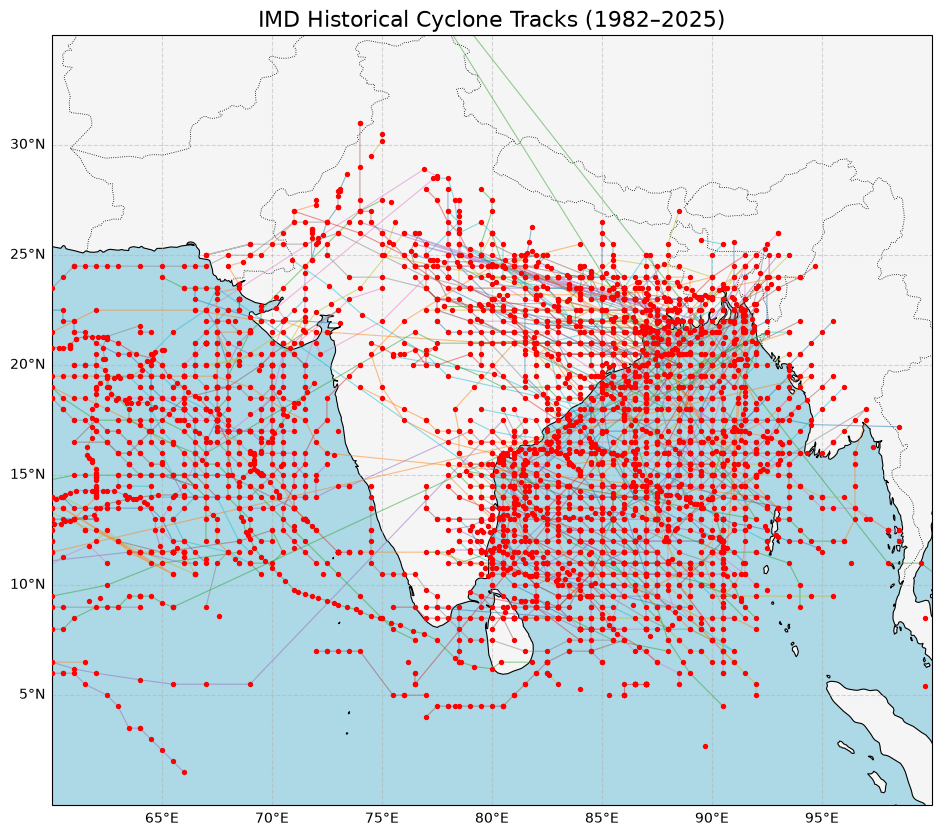

In [12]:
# Create geographical map
fig = plt.figure(figsize=(14, 10))

ax = plt.axes(
    projection=ccrs.PlateCarree()
)

# Geographic extent: Indian region
ax.set_extent(
    [60, 100, 0, 35],
    crs=ccrs.PlateCarree()
)

# Add geographical features
ax.add_feature(
    cfeature.LAND,
    facecolor="whitesmoke"
)

ax.add_feature(
    cfeature.OCEAN,
    facecolor="lightblue"
)

ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linestyle=":", linewidth=0.6)

# Gridlines
gl = ax.gridlines(
    draw_labels=True,
    linestyle="--",
    alpha=0.5
)

gl.top_labels = False
gl.right_labels = False

# Plot individual cyclone trajectories
for cyclone_id, group in track_data.groupby("Cyclone_ID"):

    group = group.sort_values("Datetime")

    ax.plot(
        group["Longitude (lon.)"],
        group["Latitude (lat.)"],
        linewidth=0.8,
        alpha=0.5,
        transform=ccrs.PlateCarree()
    )

    # Plot observation points
    ax.scatter(
        group["Longitude (lon.)"],
        group["Latitude (lat.)"],
        s=8,
        color="red",
        transform=ccrs.PlateCarree(),
        zorder=3
    )

ax.set_title(
    "IMD Historical Cyclone Tracks (1982–2025)",
    fontsize=16
)

plt.savefig(
    "outputs/all_cyclone_tracks.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### Streamlit Dashboard